First, I read in the data files

In [3]:
# Data libraries

import pandas as pd
import numpy as np
from pathlib import Path


# Plotting libraries
import matplotlib.pyplot as plt
from matplotlib import image as mpimg
import seaborn as sns

#Create figures folder 
Path("figures").mkdir(exist_ok=True)

# sklearn modules
import sklearn

df_avg = pd.read_csv("csv_files/avg_river_levels.csv")
df_min = pd.read_csv("csv_files/min_river_levels.csv")
df_max = pd.read_csv("csv_files/max_river_levels.csv")
df_locs = pd.read_csv("csv_files/monitoring_locations.csv")

def function




SyntaxError: expected '(' (1885439068.py, line 24)

Then I plotted a map showing the locations of the stations, then overlayed this on a map of Scotland using https://kepler.gl/demo? 


then we investigated missing values in the data.we plotted  timeseries to investigate how missing data changes over time, and found that the vast majority of data was missing until ??? 2018, so we cleaned the data by getting rid of ??? imputing ???? idk guys fill this in  xxxxx then i plotted a histogram to see how many stations were missing certain amounts of data, and then created a heatmap to show if the stations with lots of missing data happened to be concentrated in a certain area. Then i coloured the map of scotland by the amount of missing data to see if this made a difference. 

NOTE will need to redo this and create heatmap and histogram again once we have a new dataset. 

In [ ]:
# This code chunk filters the data

# Stations outside Scotland
# Remove all observation IDs associated with these stations
stations_to_remove = df_locs.loc[
    df_locs["Station_Name"].str.strip().str.lower().isin(
        ["portrush", "bangor", "port erin"]
    ),
    "Observation_ID"
].tolist()


# ===============
# DF AVERAGE
# ===============

# Work with data in wide form
df_avg = df_avg.replace(999999.999, np.nan)

dates1 = pd.to_datetime(df_avg.columns[3:], dayfirst=True)
vals1 = df_avg.iloc[:, 3:].copy()
vals1.columns = dates1
vals1.index = df_avg["Observation_ID"]
vals1 = vals1.T

# Full daily data with NA rows where gaps were
vals1 = vals1.reindex(pd.date_range(vals1.index.min(), vals1.index.max(), freq="D"))

# Drop stations outside Scotland
vals1 = vals1.drop(columns=stations_to_remove, errors="ignore")

# Drop big station-wide outage DAYS
good1 = vals1[vals1.isna().mean(axis=1) <= 0.5]

# Drop STATIONS missing more than 10% of remaining data
miss1 = good1.isna().mean()
keep1 = miss1.index[miss1 <= 0.1]
filtered_avg = good1[keep1]


# ===============
# DF MIN
# ===============

df_min = df_min.replace(999999.999, np.nan)

dates2 = pd.to_datetime(df_min.columns[3:], dayfirst=True)
vals2 = df_min.iloc[:, 3:].copy()
vals2.columns = dates2
vals2.index = df_min["Observation_ID"]
vals2 = vals2.T

# Full daily data with NA rows where gaps were
vals2 = vals2.reindex(pd.date_range(vals2.index.min(), vals2.index.max(), freq="D"))

# Drop stations outside Scotland
vals2 = vals2.drop(columns=stations_to_remove, errors="ignore")

# Drop big station-wide outage DAYS
good2 = vals2[vals2.isna().mean(axis=1) <= 0.5]

# Drop STATIONS missing more than 10% of remaining data
miss2 = good2.isna().mean()
keep2 = miss2.index[miss2 <= 0.1]
filtered_min = good2[keep2]


# ===============
# DF MAX
# ===============

df_max = df_max.replace(999999.999, np.nan)

dates3 = pd.to_datetime(df_max.columns[3:], dayfirst=True)
vals3 = df_max.iloc[:, 3:].copy()  # Fixed: previously used df_min
vals3.columns = dates3
vals3.index = df_max["Observation_ID"]
vals3 = vals3.T

# Full daily data with NA rows where gaps were
vals3 = vals3.reindex(pd.date_range(vals3.index.min(), vals3.index.max(), freq="D"))

# Drop stations outside Scotland
vals3 = vals3.drop(columns=stations_to_remove, errors="ignore")

# Drop big station-wide outage DAYS
good3 = vals3[vals3.isna().mean(axis=1) <= 0.5]

# Drop STATIONS missing more than 10% of remaining data
miss3 = good3.isna().mean()
keep3 = miss3.index[miss3 <= 0.1]
filtered_max = good3[keep3]


# filter the locations 

# Keep stations present in all three filtered datasets
common_stations = (
    filtered_avg.columns
    .intersection(filtered_min.columns)
    .intersection(filtered_max.columns)
)

df_locs_filtered = df_locs[
    df_locs["Observation_ID"].isin(common_stations)
].copy()

#keeping statiosn with no missing data across all datasets
complete_stations = (
    filtered_avg[common_stations].notna().all() &
    filtered_min[common_stations].notna().all() &
    filtered_max[common_stations].notna().all()
)




In [ ]:
#calculating things about the new data
# Percentage of stations with no missing observations before filtering
print("Average:", (vals1.isna().mean() == 0).mean() * 100)
print("Minimum:", (vals2.isna().mean() == 0).mean() * 100)
print("Maximum:", (vals3.isna().mean() == 0).mean() * 100)

# Percentage of stations with no missing observations after filtering
print("Filtered average:", (filtered_avg.isna().mean() == 0).mean() * 100)
print("Filtered minimum:", (filtered_min.isna().mean() == 0).mean() * 100)
print("Filtered maximum:", (filtered_max.isna().mean() == 0).mean() * 100)

print("Original stations:", len(df_locs))
print("Filtered stations:", len(df_locs_filtered))

for name, df in [("avg", filtered_avg), ("min", filtered_min), ("max", filtered_max)]:
    missing = df.isna().sum().sum()
    total = df.size
    print(f"{name} is missing {missing:,} values ({missing / total * 100:.2f}%)")

print("Days removed from average dataset:", len(vals1) - len(filtered_avg))
print("Days removed from minimum dataset:", len(vals2) - len(filtered_min))
print("Days removed from maximum dataset:", len(vals3) - len(filtered_max))
print("Percentage of days removed (average):",
      (1 - len(filtered_avg) / len(vals1)) * 100)

print("Percentage missing after filtering:",
      filtered_avg.isna().values.mean() * 100)



print("Filtered average:", (filtered_avg.isna().mean() == 0).sum())
print("Filtered minimum:", (filtered_min.isna().mean() == 0).sum())
print("Filtered maximum:", (filtered_max.isna().mean() == 0).sum())


print("Number of complete stations:", complete_stations.sum())
print("Percentage of complete stations:", complete_stations.mean() * 100)




Average: 0.0
Minimum: 0.0
Maximum: 0.0
Filtered average: 21.052631578947366
Filtered minimum: 21.052631578947366
Filtered maximum: 20.123839009287924
Original stations: 392
Filtered stations: 323
avg is missing 14,154 values (1.33%)
min is missing 14,154 values (1.33%)
max is missing 14,167 values (1.33%)
Days removed from average dataset: 1094
Days removed from minimum dataset: 1094
Days removed from maximum dataset: 1094
Percentage of days removed (average): 24.937314793708687
Percentage missing after filtering: 1.3307146503653964
Filtered average: 68
Filtered minimum: 68
Filtered maximum: 65
Number of complete stations: 65
Percentage of complete stations: 20.123839009287924


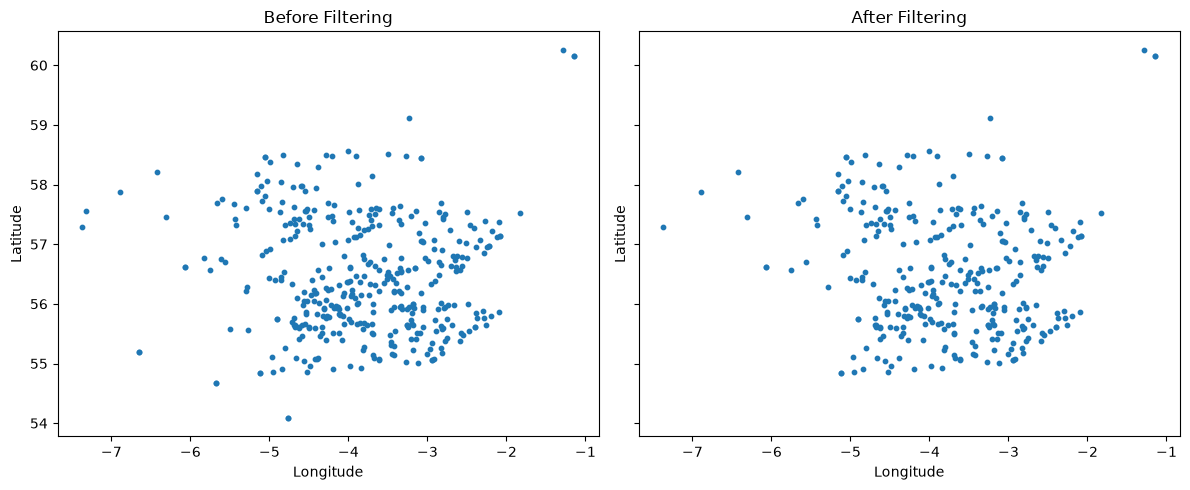

In [ ]:
#Locations of stations
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

ax[0].scatter(df_locs["Longitude"], df_locs["Latitude"], s=10)
ax[0].set_xlabel("Longitude")
ax[0].set_ylabel("Latitude")
ax[0].set_title("Before Filtering")

ax[1].scatter(df_locs_filtered["Longitude"], df_locs_filtered["Latitude"], s=10)
ax[1].set_xlabel("Longitude")
ax[1].set_ylabel("Latitude")
ax[1].set_title("After Filtering")

plt.tight_layout()
plt.savefig("figures/station_locations_before_after.png",
            dpi=300, bbox_inches="tight")
plt.show()


2017-03-31    6.501548
2017-04-01    6.501548
2017-04-02    7.120743
2017-04-03    6.501548
2017-04-04    6.811146
                ...   
2026-10-04    0.309598
2026-10-05    0.309598
2026-10-06    0.309598
2026-10-07    0.309598
2026-10-08    0.309598
Length: 3293, dtype: float64


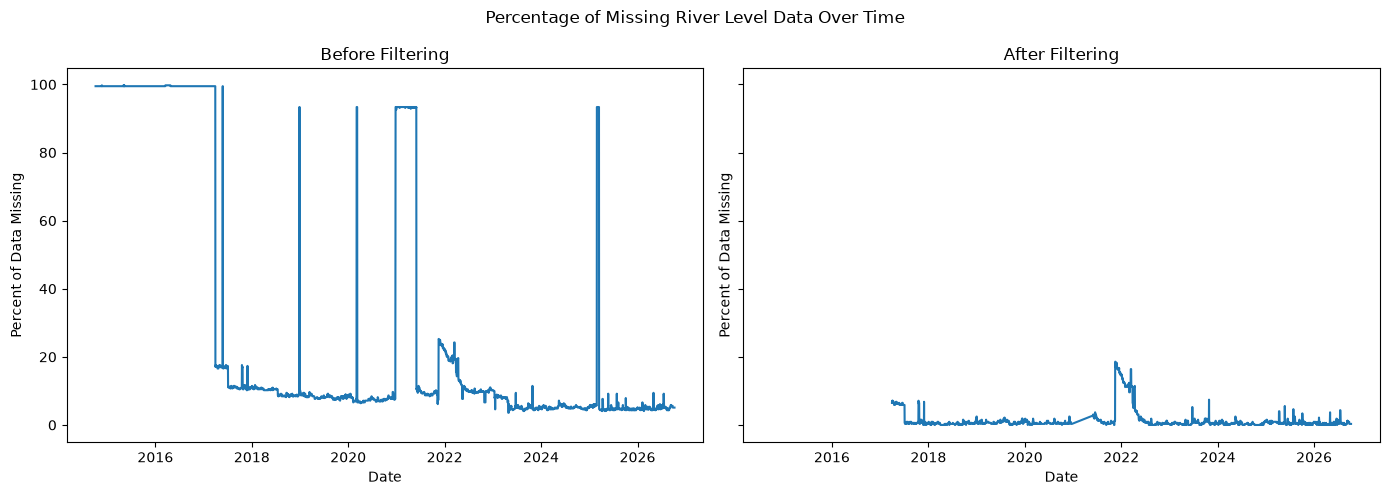

In [ ]:
# Calculate percentage missing per date
miss_unfil_row = df_avg.iloc[:, 3:].isna().mean(axis=0) * 100

miss_fil_row = filtered_avg.isna().mean(axis=1) * 100
print(miss_fil_row)

# Create side-by-side plots
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True, sharex=True)

ax[0].plot(pd.to_datetime(miss_unfil_row.index, dayfirst=True), miss_unfil_row)
ax[0].set_xlabel("Date")
ax[0].set_ylabel("Percent of Data Missing")
ax[0].set_title("Before Filtering")

ax[1].plot(pd.to_datetime(miss_fil_row.index), miss_fil_row)
ax[1].set_xlabel("Date")
ax[1].set_ylabel("Percent of Data Missing")
ax[1].set_title("After Filtering")

fig.suptitle("Percentage of Missing River Level Data Over Time")

plt.tight_layout()

# Save graph 
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/missing_over_time_before_after.png",
            dpi=300, bbox_inches="tight")

plt.show()

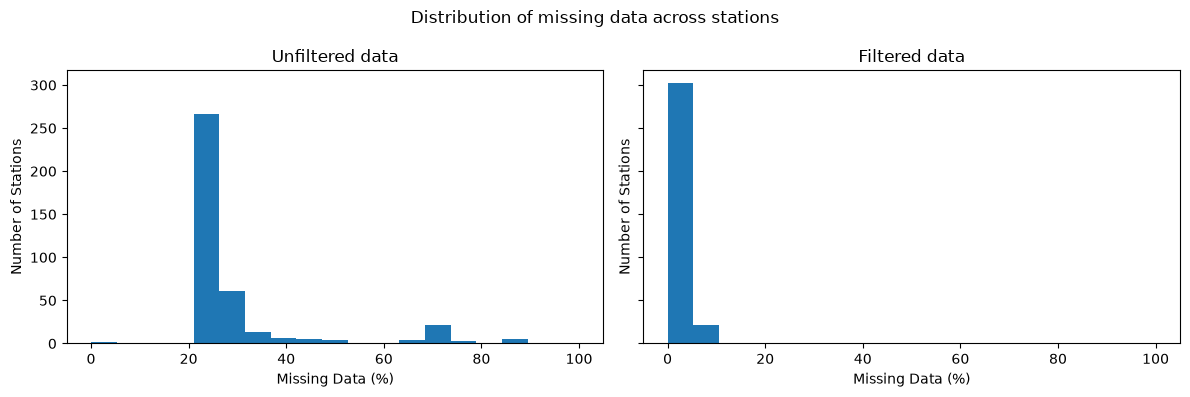

Unfiltered stations with no missing data: 0
Filtered stations with no missing data: 68


In [ ]:
#Histograms of missing data across stations 
# Unfiltered
miss_unfil = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

# Filtered
miss_fil = filtered_avg.isna().mean(axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True, sharex=True)
bins = np.linspace(0, 100, 20)

ax[0].hist(miss_unfil, bins=bins)
ax[0].set_xlabel("Missing Data (%)")
ax[0].set_ylabel("Number of Stations")
ax[0].set_title("Unfiltered data")

ax[1].hist(miss_fil, bins=bins)
ax[1].set_xlabel("Missing Data (%)")
ax[1].set_ylabel("Number of Stations")
ax[1].set_title("Filtered data")

plt.suptitle("Distribution of missing data across stations")
plt.tight_layout()
plt.savefig("figures/missing_by_station_before_after.png",
            dpi=300, bbox_inches="tight")
plt.show()

#how many are missing per station
print("Unfiltered stations with no missing data:", (miss_unfil == 0).sum())
print("Filtered stations with no missing data:", (miss_fil == 0).sum())

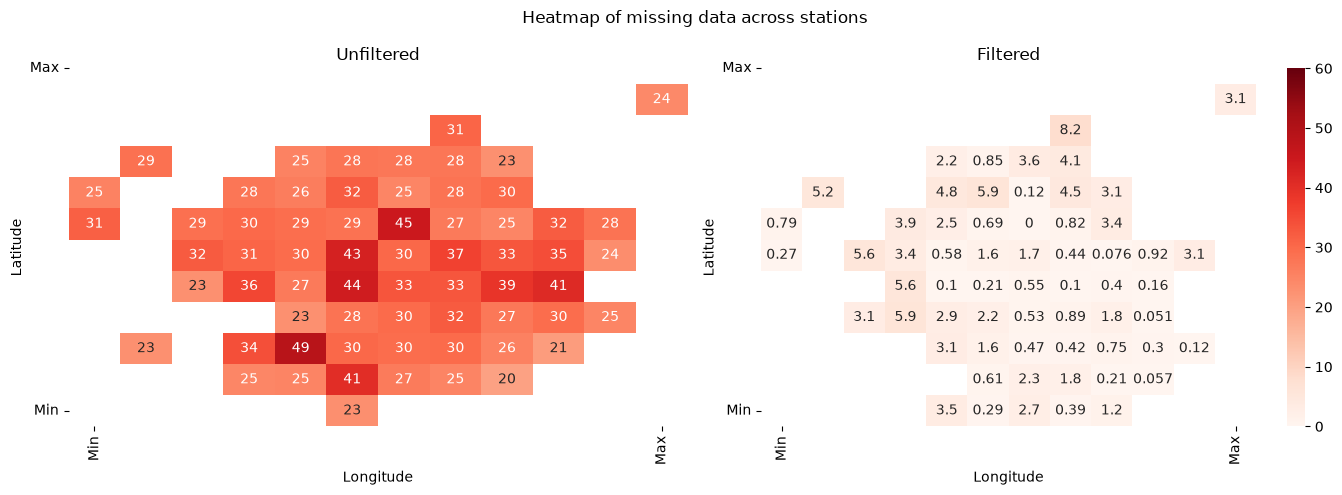

In [ ]:
#Heatmap of missing stations 
# Unfiltered
df_map_unfil = df_locs.set_index("Observation_ID").copy()
df_map_unfil["Missing"] = miss_unfil.set_axis(df_avg["Observation_ID"]).reindex(df_map_unfil.index)

# Filtered
df_map_fil = df_locs.set_index("Observation_ID").copy()
df_map_fil["Missing"] = miss_fil.reindex(df_map_fil.index)
df_map_fil = df_map_fil.loc[df_map_fil.index.intersection(miss_fil.index)]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for i, df_map in enumerate([df_map_unfil, df_map_fil]):
    df_map = df_map.copy()

    df_map["Latitude"] = pd.cut(df_map["Latitude"], bins=12)
    df_map["Longitude"] = pd.cut(df_map["Longitude"], bins=12)

    heatmap_data = df_map.pivot_table(
        values="Missing",
        index="Latitude",
        columns="Longitude",
        observed=False
    )

    sns.heatmap(heatmap_data, annot=True, cmap="Reds",
                vmin=0, vmax=60, ax=ax[i], cbar=(i == 1))

    ax[i].set_title(["Unfiltered", "Filtered"][i])
    ax[i].set_xticks([0.5, 11.5])
    ax[i].set_xticklabels(["Min", "Max"])
    ax[i].set_yticks([0.5, 11.5])
    ax[i].set_yticklabels(["Min", "Max"])
    ax[i].invert_yaxis()

plt.suptitle("Heatmap of missing data across stations")
plt.tight_layout()
plt.savefig("figures/missing_stations_heatmaps.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Water level data only - using the filtered datasets
avg = filtered_avg.T.copy()
min_level = filtered_min.T.copy()
max_level = filtered_max.T.copy()

# Make sure all three datasets contain the same stations and dates
common_stations = avg.index.intersection(min_level.index).intersection(max_level.index)
common_dates = avg.columns.intersection(min_level.columns).intersection(max_level.columns)

#Make sure order is correct 
avg = avg.sort_index(axis=1)
avg = avg.loc[common_stations, common_dates]
min_level = min_level.sort_index(axis=1)
min_level = min_level.loc[common_stations, common_dates]
max_level = max_level.sort_index(axis=1)
max_level = max_level.loc[common_stations, common_dates]


# Create new dataset using the stations remaining after filtering
df_features = df_locs.set_index("Observation_ID").loc[common_stations].copy()

# Calculating the daily range and the change between days
daily_range = max_level - min_level

# Calculate changes only between consecutive calendar days
daily_change = avg.T.asfreq("D").diff().T


# Calculating all of the features
df_features["Std_Level"] = avg.std(axis=1)
df_features["Mean_Daily_Range"] = daily_range.mean(axis=1)
df_features["Std_Daily_Range"] = daily_range.std(axis=1)
df_features["Mean_Absolute_Daily_Change"] = daily_change.abs().mean(axis=1)
df_features["Std_Daily_Change"] = daily_change.std(axis=1)
df_features["90th_Daily_Range"] = daily_range.quantile(0.90, axis=1)

# Percent of days in each station with a range above the 90th percentile
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.gt.html
threshold_range = daily_range.stack().quantile(0.90)
df_features["Percent_Range_Above_Threshold"] = (
    daily_range.gt(threshold_range).sum(axis=1)
    / daily_range.notna().sum(axis=1) * 100
)

# Percent of days in each station with a water level rise greater above the 90th percentile
threshold_rise = daily_change.stack().quantile(0.90)
df_features["Percent_Rise_Above_Threshold"] = (
    daily_change.gt(threshold_rise).sum(axis=1)
    / daily_change.notna().sum(axis=1) * 100
)
df_features = df_features.reset_index()
df_features.to_csv("df_features.csv", index=False)

df_features


,Observation_ID,County,Station_Name,Latitude,Longitude,Std_Level,Mean_Daily_Range,Std_Daily_Range,Mean_Absolute_Daily_Change,Std_Daily_Change,90th_Daily_Range,Percent_Range_Above_Threshold,Percent_Rise_Above_Threshold
0,aberdeenshire__bogie-redcraig__obs1,aberdeenshire,"Bogie, Redcraig",57.424758,-2.802015,0.204054,0.054589,0.118079,0.035133,0.086823,0.1390,1.032493,4.472163
1,aberdeenshire__dee-grampian-mar-lodge__obs1,aberdeenshire,"Dee (Grampian), Mar Lodge",56.988040,-3.486198,0.173137,0.124972,0.196497,0.069675,0.123038,0.3303,3.801703,10.091463
2,aberdeenshire__dee-grampian-park__obs1,aberdeenshire,"Dee (Grampian), Park",57.075424,-2.335825,0.377590,0.169083,0.298416,0.109434,0.213299,0.4510,6.986634,12.663623
3,aberdeenshire__dee-grampian-polhollick__obs1,aberdeenshire,"Dee (Grampian), Polhollick",57.055146,-3.083181,0.212161,0.124043,0.188722,0.076414,0.135589,0.3300,3.465046,10.390006
4,aberdeenshire__dee-grampian-woodend__obs1,aberdeenshire,"Dee (Grampian), Woodend",57.050129,-2.603567,0.298935,0.143885,0.238797,0.092331,0.172702,0.3715,4.930006,11.561928
...,...,...,...,...,...,...,...,...,...,...,...,...,...
318,wigtown__piltanton-burn-barsolus__obs1,wigtown,"Piltanton Burn, Barsolus",54.865853,-4.951331,0.250083,0.156560,0.320283,0.086144,0.190934,0.5448,8.924559,9.468599
319,wigtown__portpatrick-wigtown-tidal-level__obs2,wigtown,Portpatrick,54.842540,-5.120040,0.317472,2.836120,0.829737,0.204599,0.336254,3.6968,95.833333,24.583987
320,wigtown__portpatrick-wigtown__obs1,wigtown,Portpatrick,54.842540,-5.120040,0.312340,2.843606,0.819887,0.201374,0.329190,3.6988,95.989975,24.709576
321,wigtown__water-of-luce-airyhemming__obs1,wigtown,"Water of Luce, Airyhemming",54.900500,-4.839843,0.253437,0.193410,0.297810,0.113398,0.194660,0.5843,9.448575,14.920734


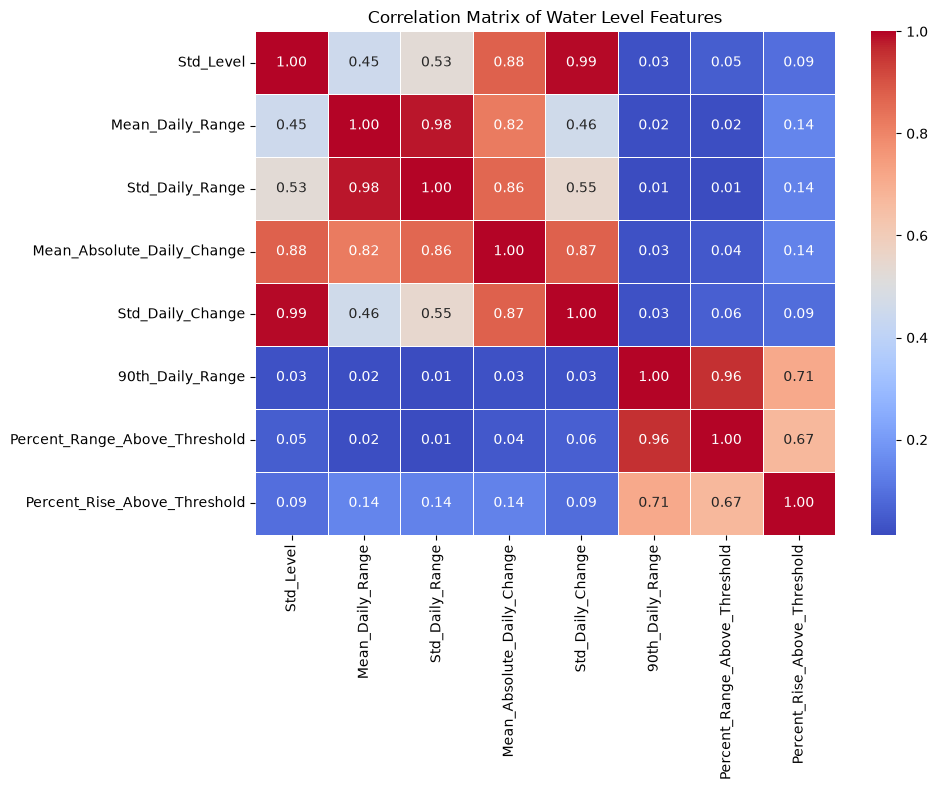

In [ ]:
#correlation matrix

df_visualise = df_features.drop(columns = ["Observation_ID","County","Station_Name","Latitude","Longitude"])

plt.figure(figsize=(10, 8))
corr_matrix = df_visualise.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Water Level Features')
plt.tight_layout()
plt.savefig("figures/correlation_features.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.show()

Index(['Std_Level', 'Mean_Daily_Range', 'Std_Daily_Range',
       'Mean_Absolute_Daily_Change', 'Std_Daily_Change', '90th_Daily_Range',
       'Percent_Range_Above_Threshold', 'Percent_Rise_Above_Threshold'],
      dtype='str')


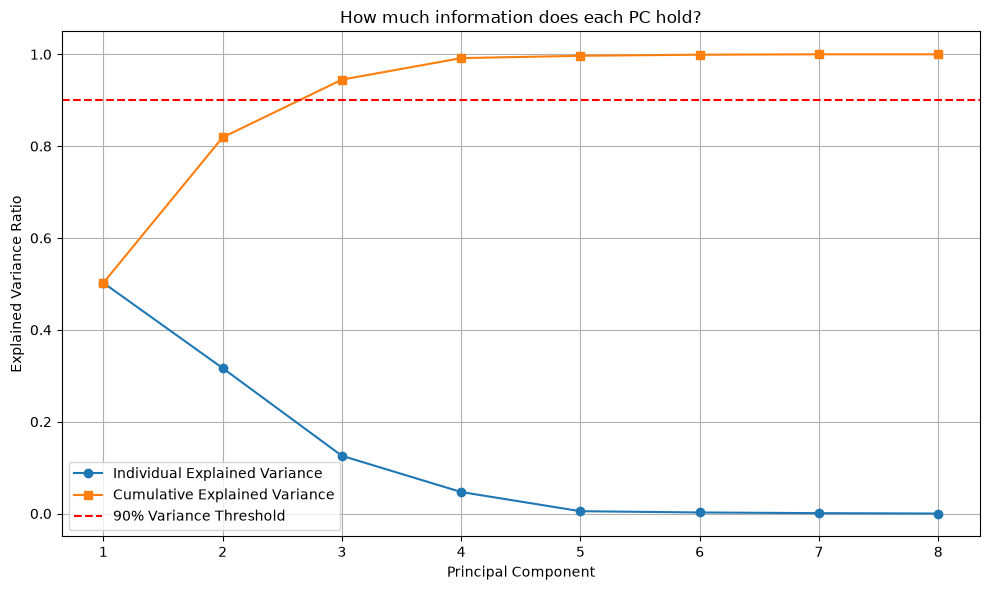

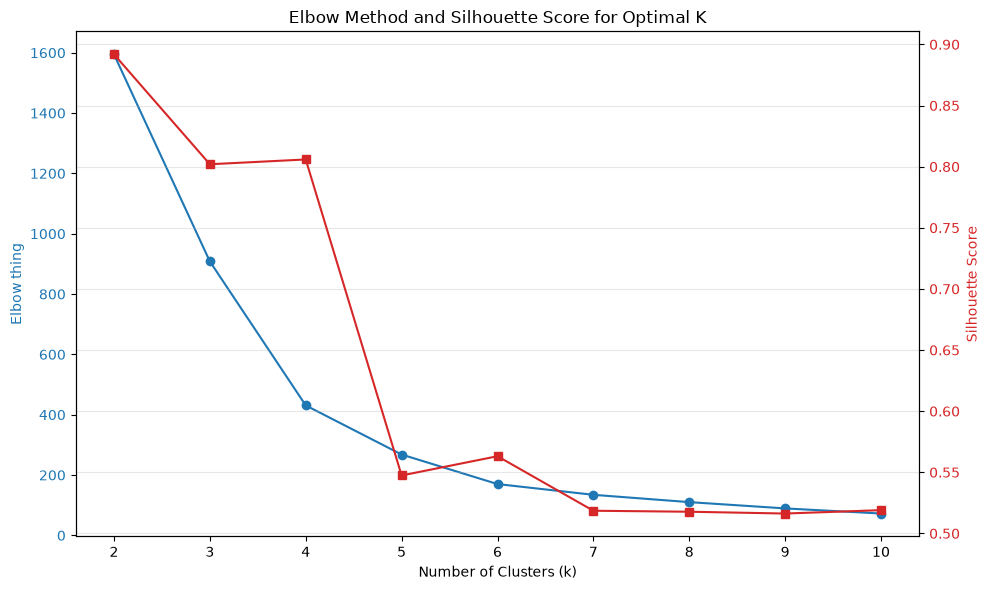

In [ ]:
from sklearn.preprocessing import StandardScaler
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
# Initialize Scaler
scaler = StandardScaler()

feature_cols = df_visualise.select_dtypes(include=[np.number]).columns
print(feature_cols)
# Fit and transform
df_scaled = scaler.fit_transform(df_visualise)
df_scaled_df = pd.DataFrame(df_scaled, columns=feature_cols, index=df_visualise.index)

# Initialize PCA
pca = PCA()
pca_result = pca.fit_transform(df_scaled)

# Explained Variance Ratio
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

# Plot Explained Variance
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker='o', label='Individual Explained Variance')
plt.plot(range(1, len(cumulative_var) + 1), cumulative_var, marker='s', label='Cumulative Explained Variance')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Variance Threshold')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('How much information does each PC hold?')
plt.legend()
plt.grid(True)
plt.savefig("figures/information_held.png",
            dpi=300, bbox_inches="tight")
plt.tight_layout()

plt.show()

inertias = []
silhouette_scores = []
K_range = range(2, 11) # Test from 2 to 10 clusters

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_scaled)
    
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, labels))

# Plot Elbow and Silhouette
fig, ax1 = plt.subplots(figsize=(10, 6))

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Elbow thing', color=color)
ax1.plot(K_range, inertias, marker='o', color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(K_range, silhouette_scores, marker='s', color=color)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Elbow Method and Silhouette Score for Optimal K')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/elbow_silhouette.png",
            dpi=300, bbox_inches="tight")
plt.show()

Feature contributions to PC1 and PC2:
                                    PC1       PC2
Std_Level                      0.428990 -0.066275
Mean_Daily_Range               0.412509 -0.061323
Std_Daily_Range                0.435384 -0.070940
Mean_Absolute_Daily_Change     0.493803 -0.075927
Std_Daily_Change               0.431897 -0.066603
90th_Daily_Range               0.070477  0.602817
Percent_Range_Above_Threshold  0.077280  0.591917
Percent_Rise_Above_Threshold   0.122186  0.512698


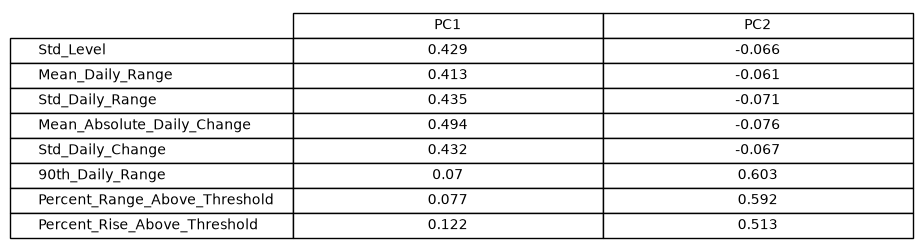

In [ ]:
pca_2d = PCA(n_components=2)
components_2d = pca_2d.fit_transform(df_scaled)
loadings = pd.DataFrame(pca_2d.components_.T, columns=['PC1', 'PC2'], index=feature_cols)
print("Feature contributions to PC1 and PC2:")
print(loadings)
fig, ax = plt.subplots(figsize=(8, 3))

ax.axis("off")

table = ax.table(
    cellText=loadings.round(3).values,
    rowLabels=loadings.index,
    colLabels=loadings.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)

plt.savefig("figures/pca_loadings.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
!jupyter nbconvert --to pdf project_saba_clean_new.ipynb --template=latex --template-file=compact.tex.j2

[NbConvertApp] Converting notebook project_saba_clean_new.ipynb to pdf
[NbConvertApp] Support files will be in project_saba_clean_new_files/
[NbConvertApp] Making directory ./project_saba_clean_new_files
[NbConvertApp] Writing 96378 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']


[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 624357 bytes to project_saba_clean_new.pdf


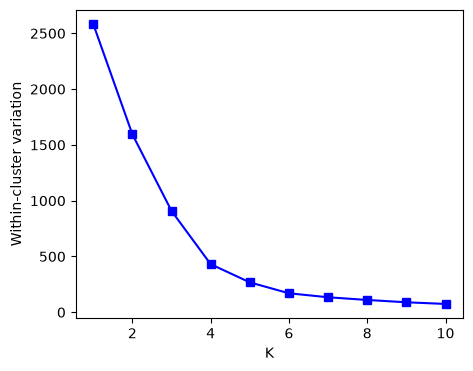

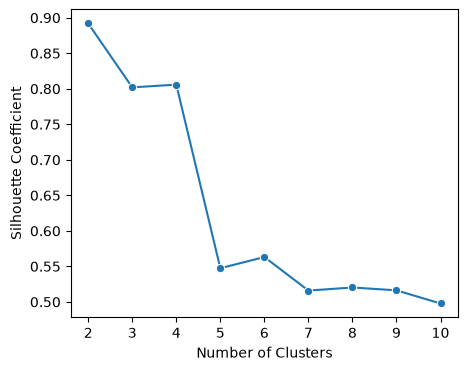

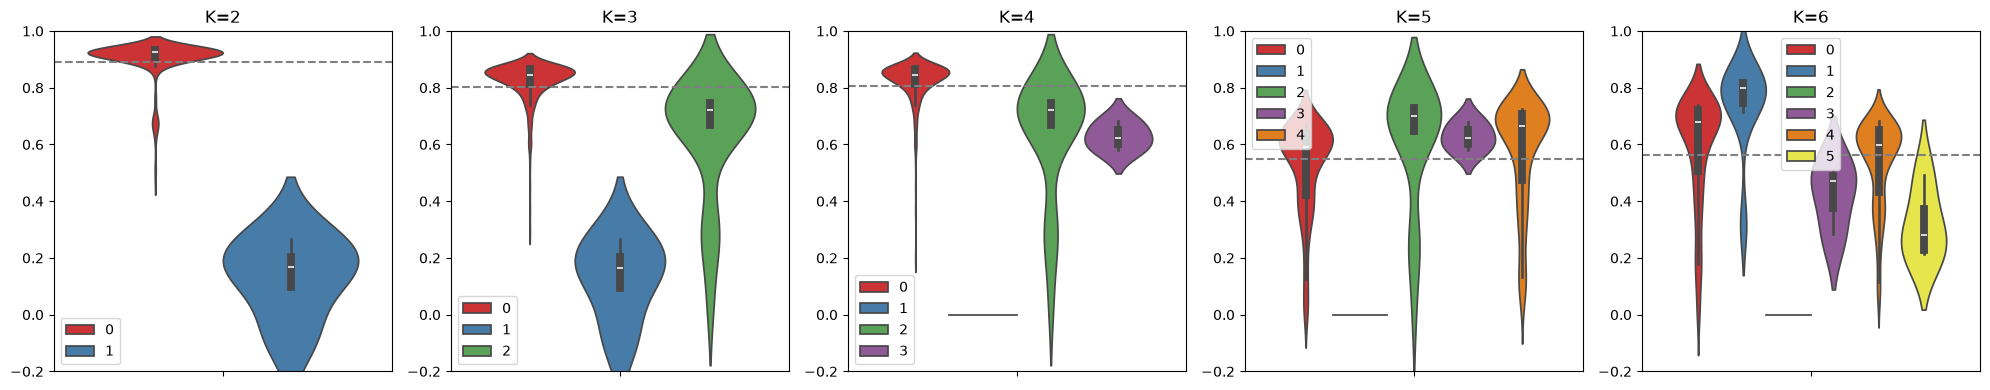

Cluster
0.0    157
4.0    142
2.0     20
3.0      3
1.0      1
Name: count, dtype: int64


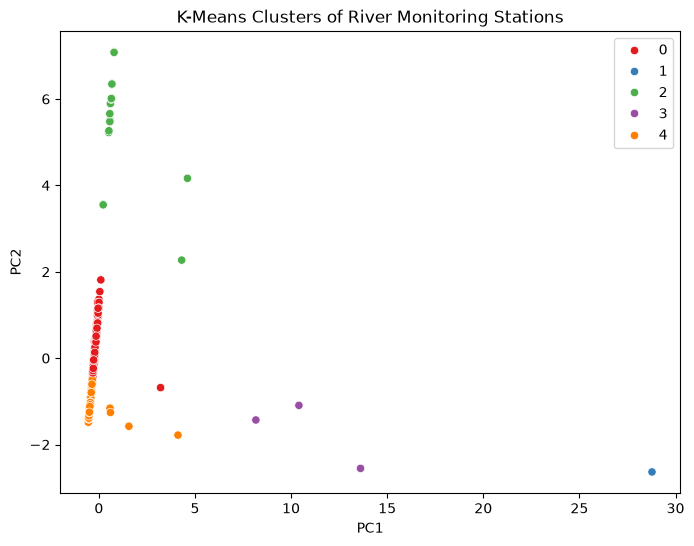

In [ ]:
#CLUSTERING WEEK 3 WORKSHOP ADAPTATION

#ex 7 adaptation, preparing the data 
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

# Choose river behaviour features - NOTE discuss with emma and gabi what features they want to put bc idk
features = [
"Std_Level",
"Mean_Daily_Range",
"Std_Daily_Range",
"Mean_Absolute_Daily_Change",
"Std_Daily_Change",
"90th_Daily_Range",
"Percent_Rise_Above_Threshold",
"Percent_Range_Above_Threshold"
]

X = df_features[features].dropna()

# Standardise data 
ss = StandardScaler()
Xs = ss.fit_transform(X)

#workshop 5 adaptation, elbow plot
# Workshop Exercise 5: Within-cluster variation

K = np.arange(1, 11)
WCV = np.zeros(K.shape)

for i in range(K.shape[0]):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(Xs)
    WCV[i] = kmeans_K.inertia_

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(K, WCV, c='b', marker='s')
plt.xlabel('K')
plt.ylabel('Within-cluster variation')
plt.show()

#ex 6 - silhouette analysis
# Workshop Exercise 6: Silhouette scores

K = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10])
silhouette_coeffs = np.zeros(K.shape)

for i in range(K.shape[0]):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(Xs)
    labs = kmeans_K.predict(Xs)

    silhouette_coeffs[i] = silhouette_score(Xs, labs)

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
sns.lineplot(x=K, y=silhouette_coeffs, marker='o', ax=ax)
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Coefficient')
plt.show()

#ex 6 - violin plots 
# Workshop Exercise 6: Silhouette sample distributions

fig, ax = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(Xs)
    labs = kmeans_K.labels_
    silhouette_samps = silhouette_samples(Xs, labs)

    sns.violinplot(y=silhouette_samps, hue=labs,
                   ax=ax[i], palette='Set1')

    ax[i].axhline(silhouette_samps.mean(), ls='--', c='gray')
    ax[i].set_title(f'K={K[i]}')
    ax[i].set_ylim([-0.2, 1])

plt.tight_layout()
plt.show()

#k means clustering by ex 12 

kmeans = KMeans(n_clusters=5, n_init=20, random_state=0).fit(Xs)

df_features["Cluster"] = np.nan
df_features.loc[X.index, "Cluster"] = kmeans.labels_

print(df_features["Cluster"].value_counts())

#PCA analysis - adapted from ex 10 and 13
# Workshop Exercises 10 and 13: PCA visualisation

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
scores = pca.fit_transform(Xs)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

sns.scatterplot(
    x=scores[:, 0],
    y=scores[:, 1],
    hue=kmeans.labels_,
    palette='Set1',
    ax=ax
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('K-Means Clusters of River Monitoring Stations')

plt.show()

#table of the stats for each of the clusters
df_features.groupby("Cluster")[features].median()

df_map = df_locs.merge(
    df_features[["Observation_ID", "Cluster"]],
    on="Observation_ID"
)

df_map.to_csv("station_clusters.csv", index=False)

NameError: name 'filtered_avg' is not defined